# Set G – Bank Loan Default

**Dataset:** `set_G_loan_default.csv`  



## 1. Read the CSV file

In [1]:
data <- read.csv("set_G_loan_default.csv")

head(data)
names(data)
summary(data)

,applicant_id,age,annual_income_lakhs,loan_amount_lakhs,credit_score,dependents,defaulted
,<int>,<int>,<dbl>,<dbl>,<int>,<int>,<int>
1,1,37,6.9,11.0,611,1,1
2,2,21,8.7,5.2,666,2,0
3,3,55,12.7,16.1,601,3,0
4,4,32,4.4,12.3,748,2,1
5,5,32,7.6,11.7,743,1,1
6,6,39,16.0,9.3,698,1,0


[1] "applicant_id"        "age"                 "annual_income_lakhs"
[4] "loan_amount_lakhs"   "credit_score"        "dependents"         
[7] "defaulted"

  applicant_id      age        annual_income_lakhs loan_amount_lakhs
 Min.   :  1   Min.   :21.00   Min.   : 2.500      Min.   : 2.70    
 1st Qu.: 37   1st Qu.:32.00   1st Qu.: 5.400      1st Qu.: 7.10    
 Median : 73   Median :39.00   Median : 6.800      Median :10.20    
 Mean   : 73   Mean   :38.55   Mean   : 7.648      Mean   :12.62    
 3rd Qu.:109   3rd Qu.:46.00   3rd Qu.: 9.100      3rd Qu.:16.40    
 Max.   :145   Max.   :57.00   Max.   :22.100      Max.   :40.50    
  credit_score     dependents      defaulted     
 Min.   :520.0   Min.   :0.000   Min.   :0.0000  
 1st Qu.:656.0   1st Qu.:1.000   1st Qu.:0.0000  
 Median :689.0   Median :1.000   Median :0.0000  
 Mean   :694.8   Mean   :1.628   Mean   :0.4552  
 3rd Qu.:743.0   3rd Qu.:2.000   3rd Qu.:1.0000  
 Max.   :837.0   Max.   :7.000   Max.   :1.0000  

## Q1. Mean, Median, Standard Deviation, Variance and Mode (8 marks)

In [2]:
# Loan amount statistics
mean(data$loan_amount_lakhs)
median(data$loan_amount_lakhs)
sd(data$loan_amount_lakhs)
var(data$loan_amount_lakhs)

# Mode of dependents
tab <- table(data$dependents)
tab
names(tab)[which.max(tab)]

# Compare mean and median
mean(data$loan_amount_lakhs)
median(data$loan_amount_lakhs)

[1] 12.62207

[1] 10.2

[1] 7.502319

[1] 56.28479


 0  1  2  3  4  5  6  7 
30 49 33 22  3  6  1  1 

[1] "1"

[1] 12.62207

[1] 10.2

**Comment:** Compare the mean and median values. If they are close, write: “The mean and median are close to each other.”

## Q2. Confidence Interval, Quartiles, Deciles, Percentile and IQR (8 marks)

In [3]:
# 95% confidence interval for mean
t.test(data$annual_income_lakhs)$conf.int

# Quartiles
quantile(data$annual_income_lakhs, c(0.25, 0.50, 0.75))

# Deciles D1 to D9
quantile(data$annual_income_lakhs, seq(0.1, 0.9, 0.1))

# 90th percentile
quantile(data$annual_income_lakhs, 0.90)

# Interquartile range
IQR(data$annual_income_lakhs)

[1] 7.073946 8.221226
attr(,"conf.level")
[1] 0.95

25% 50% 75% 
5.4 6.8 9.1

10%   20%   30%   40%   50%   60%   70%   80%   90% 
 4.00  4.80  5.72  6.30  6.80  7.64  8.60  9.80 11.96

90% 
11.96

[1] 3.7

## Q3. Skewness, Kurtosis and Histograms (8 marks)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependency ‘proxy’




[1] 1.355292

[1] -0.06440504

[1] 2.323769

[1] -0.2976964

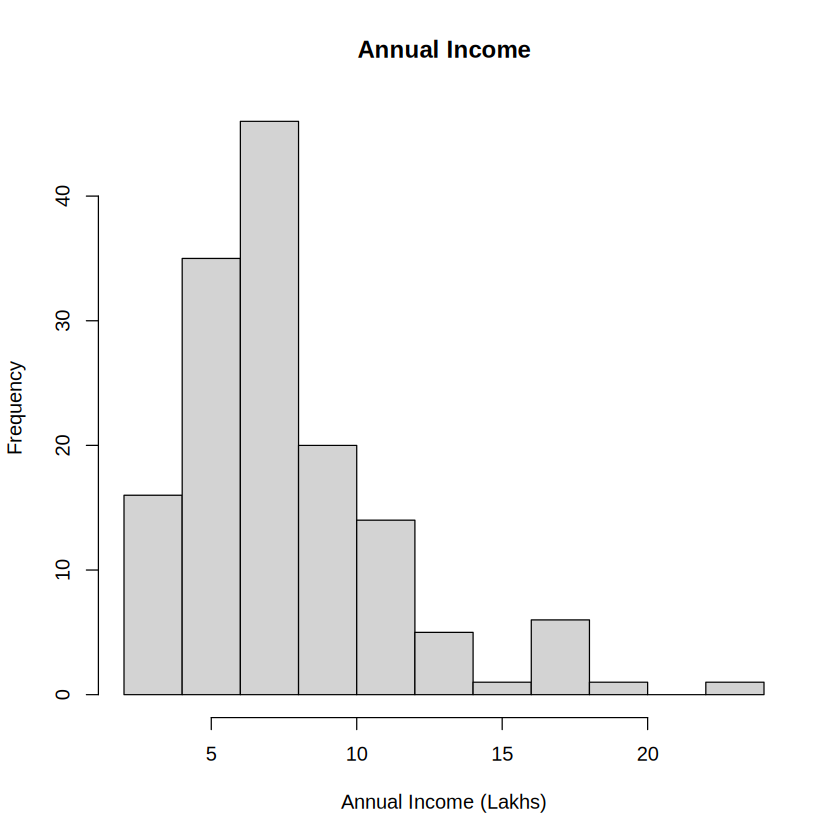

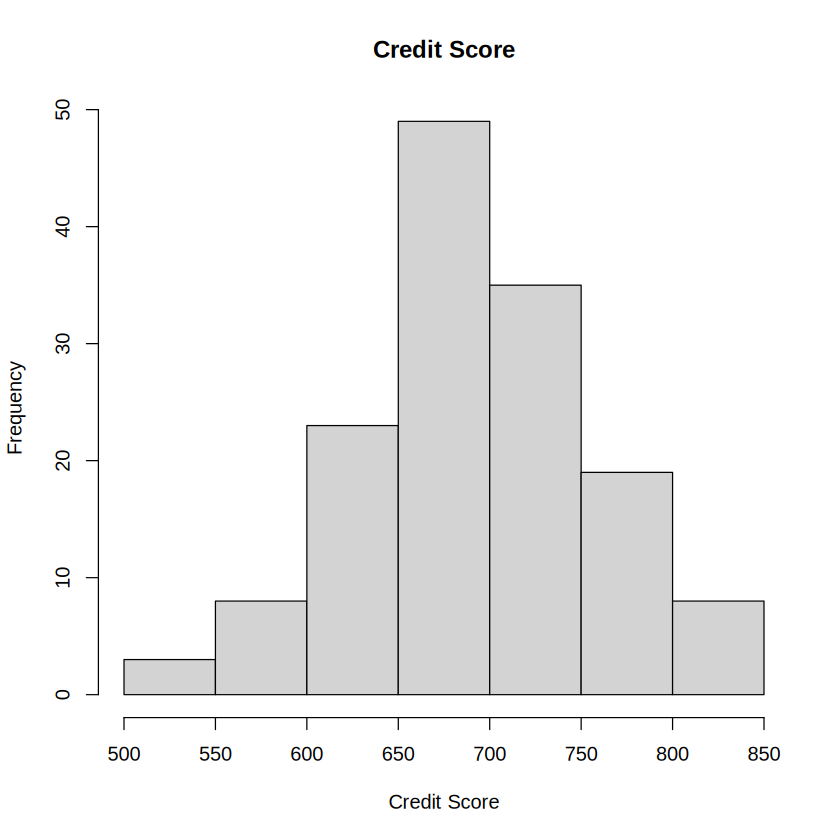

In [5]:
# Install package once if needed
install.packages("e1071", repos = "http://cran.us.r-project.org")
library(e1071)

# Skewness
skewness(data$annual_income_lakhs)
skewness(data$credit_score)

# Kurtosis
kurtosis(data$annual_income_lakhs)
kurtosis(data$credit_score)

# Histogram of annual income
hist(data$annual_income_lakhs,
     main = "Annual Income",
     xlab = "Annual Income (Lakhs)")

# Histogram of credit score
hist(data$credit_score,
     main = "Credit Score",
     xlab = "Credit Score")

**Comment:**
- Compare the absolute skewness values. The larger absolute value is more skewed.
- For Pearson kurtosis, above 3 is more peaked; below 3 is flatter than a normal curve.

## Q4(a). Correlation and Simple Linear Regression (8 marks)

[1] 0.09979696


	Pearson's product-moment correlation

data:  data$annual_income_lakhs and data$loan_amount_lakhs
t = 1.1994, df = 143, p-value = 0.2324
alternative hypothesis: true correlation is not equal to 0
95 percent confidence interval:
 -0.0642576  0.2585993
sample estimates:
       cor 
0.09979696 



Call:
lm(formula = loan_amount_lakhs ~ annual_income_lakhs, data = data)

Residuals:
   Min     1Q Median     3Q    Max 
-9.562 -5.562 -2.133  3.874 27.845 

Coefficients:
                    Estimate Std. Error t value Pr(>|t|)    
(Intercept)          10.9836     1.5010   7.317 1.67e-11 ***
annual_income_lakhs   0.2142     0.1786   1.199    0.232    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 7.491 on 143 degrees of freedom
Multiple R-squared:  0.009959,	Adjusted R-squared:  0.003036 
F-statistic: 1.439 on 1 and 143 DF,  p-value: 0.2324


1 
14.19726

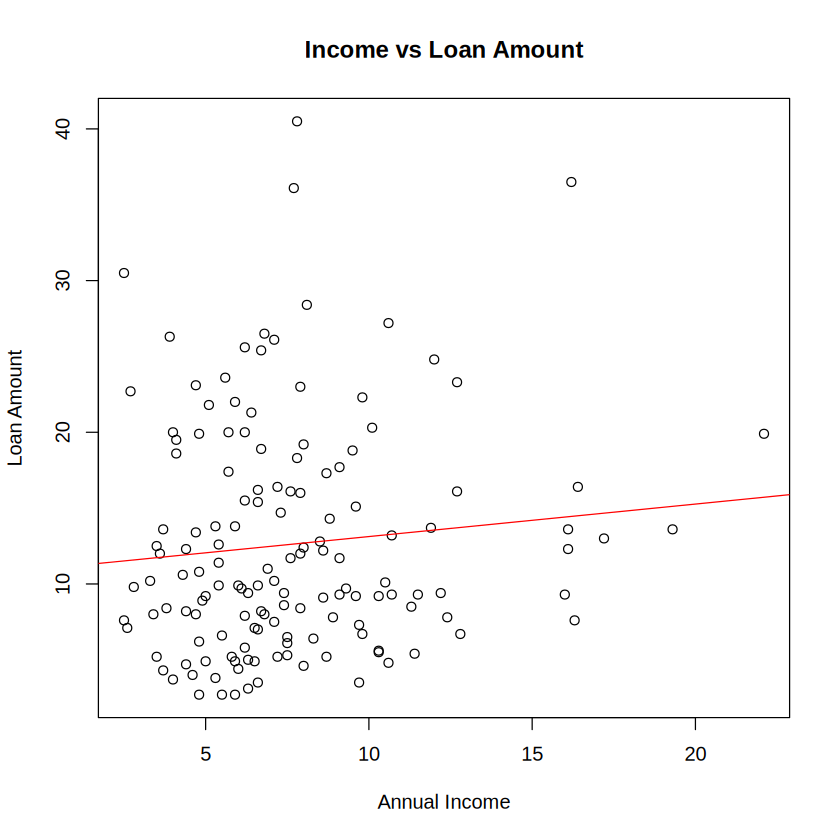

In [6]:
# Pearson correlation
cor(data$annual_income_lakhs, data$loan_amount_lakhs)

# Correlation significance test
cor.test(data$annual_income_lakhs, data$loan_amount_lakhs)

# Simple linear regression
model <- lm(loan_amount_lakhs ~ annual_income_lakhs, data = data)

# Model summary
summary(model)

# Scatter plot
plot(data$annual_income_lakhs, data$loan_amount_lakhs,
     main = "Income vs Loan Amount",
     xlab = "Annual Income",
     ylab = "Loan Amount")

# Regression line
abline(model, col = "red")

# Predict loan amount when income = 15
predict(model, data.frame(annual_income_lakhs = 15))

## Q4(b). Logistic Regression (8 marks)

In [7]:
# Logistic regression
model2 <- glm(defaulted ~ credit_score + loan_amount_lakhs +
              annual_income_lakhs,
              data = data, family = binomial)

# Model summary
summary(model2)

# Odds ratios
exp(coef(model2))

# Predict probability for the given applicant
newdata <- data.frame(credit_score = 680,
                      loan_amount_lakhs = 20,
                      annual_income_lakhs = 9)

prob <- predict(model2, newdata, type = "response")
prob

# Predicted class using 0.5 cut-off
ifelse(prob >= 0.5, 1, 0)

# Confusion matrix
pred <- predict(model2, type = "response")
pred_class <- ifelse(pred >= 0.5, 1, 0)

table(Actual = data$defaulted, Predicted = pred_class)

# Accuracy
mean(pred_class == data$defaulted) * 100


Call:
glm(formula = defaulted ~ credit_score + loan_amount_lakhs + 
    annual_income_lakhs, family = binomial, data = data)

Coefficients:
                    Estimate Std. Error z value Pr(>|z|)    
(Intercept)         12.72652    2.81483   4.521 6.15e-06 ***
credit_score        -0.01548    0.00374  -4.138 3.50e-05 ***
loan_amount_lakhs    0.08115    0.02999   2.705  0.00682 ** 
annual_income_lakhs -0.43961    0.09379  -4.687 2.77e-06 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

(Dispersion parameter for binomial family taken to be 1)

    Null deviance: 199.85  on 144  degrees of freedom
Residual deviance: 144.69  on 141  degrees of freedom
AIC: 152.69

Number of Fisher Scoring iterations: 5


(Intercept)        credit_score   loan_amount_lakhs annual_income_lakhs 
       3.365549e+05        9.846427e-01        1.084533e+00        6.442854e-01

1 
0.4673029

1 
0

      Predicted
Actual  0  1
     0 61 18
     1 20 46

[1] 73.7931

## Quick Revision

| Question | Main R functions |
|---|---|
| Q1 | `mean()`, `median()`, `sd()`, `var()`, `table()` |
| Q2 | `t.test()`, `quantile()`, `IQR()` |
| Q3 | `skewness()`, `kurtosis()`, `hist()` |
| Q4(a) | `cor()`, `cor.test()`, `lm()`, `plot()`, `abline()`, `predict()` |
| Q4(b) | `glm()`, `summary()`, `exp()`, `ifelse()`, `table()` |

**Exam tip:** Use the exact column names. Round answers to four decimal places if required.
